# 1. Import and Explore the Data

**Homework — Group 34**

This notebook inspects `train.csv`, `test.csv` and `clientes.csv`: it describes the observations and variables, checks data quality and consistency, and explores the univariate and multivariate relationships that will guide preprocessing, feature selection and validation.

### 1.0 Setup
Import the libraries, fix the random seed and point to the data folder.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import f1_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

TARGET = "repeat_purchase_90d"

# Folder that holds the four CSV files (train, test, clientes, sample_submission).
# Change this single line if the files are elsewhere on your machine.
DATA_DIR = Path("data")

sns.set_theme(style="whitegrid")
PLOT_BLUE, PLOT_ORANGE = "#1779A8", "#C96A00"
FIGSIZE = (10, 6)
pd.set_option("display.max_columns", None)
warnings.filterwarnings("ignore", category=FutureWarning)

### 1.1 Load the tables and check that they fit together

In [2]:
train = pd.read_csv(DATA_DIR / "train.csv", parse_dates=["purchase_date"]).set_index("ID")
test = pd.read_csv(DATA_DIR / "test.csv", parse_dates=["purchase_date"]).set_index("ID")
clientes = pd.read_csv(DATA_DIR / "clientes.csv")
sample = pd.read_csv(DATA_DIR / "sample_submission.csv")

for name, frame in [("train", train), ("test", test), ("clientes", clientes), ("sample", sample)]:
    print(f"{name:9s} {frame.shape[0]:>5,} rows x {frame.shape[1]} columns")

print("\ntest IDs match sample_submission:", sample["ID"].tolist() == test.index.tolist())
print("ID unique in train / test:", train.index.is_unique, "/", test.index.is_unique)
print("columns only in train:", sorted(set(train.columns) - set(test.columns)))

train     6,534 rows x 38 columns
test        986 rows x 37 columns
clientes  1,143 rows x 13 columns
sample      986 rows x 2 columns

test IDs match sample_submission: True
ID unique in train / test: True / True
columns only in train: ['repeat_purchase_90d']


<div class="alert alert-block alert-warning">

- Train has 6,534 rows and test 986 (about 15% of the size of train);
- `ID` is unique in both files and the test IDs match the submission template in the same order. `ID` is kept as the index, to rebuild the submission, and is never used as a feature;
- The target is the only column missing from test.

</div>

### 1.2 Column roles and the target

30 numeric columns:
  ['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo', 'N_ Detalhes', 'invoice_count_current_purchase', 'days_since_previous_purchase', 'customer_tenure_days', 'prior_purchase_count', 'prior_total_spend', 'prior_mean_purchase_value', 'prior_std_purchase_value', 'prior_min_purchase_value', 'prior_max_purchase_value', 'prior_mean_gap_days', 'prior_std_gap_days', 'purchase_count_30d', 'spend_30d', 'purchase_count_90d', 'spend_90d', 'purchase_count_180d', 'spend_180d', 'purchase_count_365d', 'spend_365d', 'customer_id', 'random_noise']

6 categorical columns:
  ['payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series']

                     rows   share
repeat_purchase_90d              
1                    3654  0.5592
0                    2880  0.4408

F1 of predicting 'repeat' for every row: 0.7173


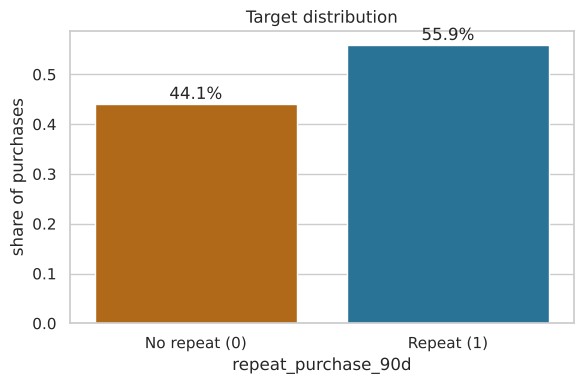

In [3]:
categorical = train.select_dtypes(include=["object", "string"]).columns.tolist()
numeric = [c for c in train.select_dtypes(include="number").columns if c != TARGET]

print(f"{len(numeric)} numeric columns:\n  {numeric}\n")
print(f"{len(categorical)} categorical columns:\n  {categorical}\n")

target_share = train[TARGET].value_counts(normalize=True).sort_index()
print(train[TARGET].value_counts().to_frame("rows").assign(share=target_share.round(4)))

always_repeat = np.ones(len(train), dtype=int)
print(f"\nF1 of predicting 'repeat' for every row: {f1_score(train[TARGET], always_repeat):.4f}")

fig, ax = plt.subplots(figsize=(6, 4))
labels = ["No repeat (0)", "Repeat (1)"]
sns.barplot(x=labels, y=target_share.values, hue=labels, palette=[PLOT_ORANGE, PLOT_BLUE], legend=False, ax=ax)
for i, share in enumerate(target_share.values):
    ax.text(i, share + 0.01, f"{share:.1%}", ha="center")
ax.set(xlabel=TARGET, ylabel="share of purchases", title="Target distribution")
plt.tight_layout()
plt.show()

<div class="alert alert-block alert-warning">

- 30 columns are stored as numbers and 6 as text;
- 2 numeric columns are not quantities: `customer_id` (a label) and `random_noise` (see 1.6);
- The target has no missing values and is mildly imbalanced: 55.9% repeat, 44.1% not. Both classes are well represented;
- Answering "repeat" for every row already scores F1 0.717 on the positive class, which is the bar any model has to beat.

</div>

### 1.3 Descriptive statistics

In [4]:
print(train[numeric].describe().T.round(2).to_string())
print()
summary = train[categorical].describe().T
summary["top share (%)"] = (100 * summary["freq"] / summary["count"]).astype(float).round(1)
print(summary.to_string())

                                 count        mean          std        min        25%        50%        75%           max
Total a Pagar                   6469.0      925.56      1335.00       0.93     188.92     476.74    1087.67  2.229721e+04
Total Bruto                     6469.0      886.15      1327.64       0.83     175.74     445.74    1036.70  2.157828e+04
Total Liquido                   6469.0      773.34      1136.36       0.76     154.38     389.91     903.37  1.812781e+04
Total Imp_                      6469.0      152.22       225.26       0.00      29.93      79.74     184.84  4.169400e+03
Total Portes                    6469.0        1.15         5.84       0.00       0.00       0.00       0.00  1.810600e+02
Total Desc_ Global              6469.0        0.35         5.12       0.00       0.00       0.00       0.00  2.184900e+02
Total Desc_ Linha               6469.0      112.47       289.99       0.00       0.00      13.13      92.28  4.103440e+03
Custo                   

<div class="alert alert-block alert-warning">

- Most columns have 6,469 values instead of 6,534: 65 rows are missing almost everything (see 1.4);
- Means far above medians (e.g. `Total a Pagar` 926 vs 477, `prior_total_spend` 18,908 vs 6,754) indicate strong right skew in money columns;
- Impossible extremes: `prior_mean_purchase_value` and `spend_365d` reach 1e9 and go negative, and day counts reach -4. A handful of such values inflate the mean of `prior_mean_purchase_value` to 2.8 million while its median stays at 725;
- Near-constant columns: `Total Portes` and `Total Desc_ Global` are 0 in over 75% of rows, `invoice_count_current_purchase` is almost always 1, `commercial_zone` has one level in 96.8% of rows and `warehouse` one level in 99.7%. They are likely to carry little information;
- `transport_method` has 80 levels, many of them rare; one-hot encoding would create about 80 sparse columns;
- `payment_type`, `salesperson` and `document_series` have few levels and are not dominated by a single one.

</div>

### 1.4 Missing values, empty rows and duplicates

In [5]:
missing = (pd.DataFrame({"train gaps": train.isna().sum(),
                         "train %": (train.isna().mean() * 100).round(2),
                         "test gaps": test.isna().sum(),
                         "test %": (test.isna().mean() * 100).round(2)})
           .query("`train gaps` > 0")
           .sort_values("train gaps", ascending=False))
print(missing.to_string())

gaps_per_row_train = train.isna().sum(axis=1)
gaps_per_row_test = test.isna().sum(axis=1)
print("\nrows by number of gaps:")
print(pd.DataFrame({"train": gaps_per_row_train.value_counts(),
                    "test": gaps_per_row_test.value_counts()}).fillna(0).astype(int).sort_index().to_string())

                                train gaps  train %  test gaps  test %
prior_std_gap_days                    1478    22.62       69.0    7.00
prior_mean_gap_days                   1308    20.02       76.0    7.71
prior_std_purchase_value              1113    17.03       46.0    4.67
prior_mean_purchase_value              862    13.19       52.0    5.27
days_since_previous_purchase           861    13.18       52.0    5.27
prior_max_purchase_value               668    10.22       22.0    2.23
prior_min_purchase_value               668    10.22       22.0    2.23
transport_method                       261     3.99       30.0    3.04
spend_365d                             260     3.98       30.0    3.04
payment_type                           260     3.98       30.0    3.04
warehouse                              260     3.98       30.0    3.04
salesperson                            259     3.96       30.0    3.04
Total Desc_ Global                      65     0.99        0.0    0.00
Total 

In [6]:
empty_rows = gaps_per_row_train >= train.shape[1] - 5
print(f"{empty_rows.sum()} nearly empty rows")
print("columns still filled in them:",
      train.loc[empty_rows].notna().sum()[lambda s: s > 0].to_dict())

print(f"\nduplicated rows (extra copies): {train.duplicated().sum()}")
print(f"rows involved in a duplication: {train.duplicated(keep=False).sum()}")

filled = train.loc[~empty_rows]
print("duplicates once the empty rows are set aside:", filled.duplicated().sum())
print("duplicated rows in test:", test.duplicated().sum())

65 nearly empty rows
columns still filled in them: {'repeat_purchase_90d': 65, 'customer_id': 65}

duplicated rows (extra copies): 10
rows involved in a duplication: 16
duplicates once the empty rows are set aside: 0
duplicated rows in test: 0


<div class="alert alert-block alert-warning">

- 65 training rows are empty records: they keep only `customer_id` and the target, and every one of the 36 other columns is missing;
- The test file has no such row: every column with exactly 65 gaps in train has 0 gaps in test;
- The 10 "duplicates" are these same empty rows; once they are set aside no duplicate remains, so no real purchase has to be removed for being duplicated;
- From here on, the exploration uses `filled` (train without the empty rows).

</div>

### 1.5 Are the remaining gaps all of one kind?

In [7]:
history = (filled["prior_purchase_count"].clip(upper=3).astype(int)
           .map({0: "0", 1: "1", 2: "2", 3: "3+"}))
prior_cols = ["days_since_previous_purchase", "prior_mean_purchase_value",
              "prior_min_purchase_value", "prior_max_purchase_value",
              "prior_std_purchase_value", "prior_mean_gap_days", "prior_std_gap_days"]

print("% missing by number of previous purchases:")
print(filled[prior_cols].isna().groupby(history).mean().mul(100).round(1).T.to_string())

print("\nrepeat rate by number of previous purchases:")
print(filled.groupby(history)[TARGET].agg(rows="size", repeat_rate="mean").round(3).to_string())

% missing by number of previous purchases:
prior_purchase_count              0      1      2   3+
days_since_previous_purchase  100.0    4.3    5.5  3.0
prior_mean_purchase_value     100.0    4.5    3.0  3.2
prior_min_purchase_value      100.0    0.0    0.0  0.0
prior_max_purchase_value      100.0    0.0    0.0  0.0
prior_std_purchase_value      100.0  100.0    0.0  0.0
prior_mean_gap_days           100.0  100.0    5.8  3.4
prior_std_gap_days            100.0  100.0  100.0  0.0

repeat rate by number of previous purchases:
                      rows  repeat_rate
prior_purchase_count                   
0                      603        0.333
1                      445        0.373
2                      365        0.400
3+                    5056        0.615


<div class="alert alert-block alert-warning">

We find three kinds of missing values:

1. **Structural.** With 0 previous purchases every `prior_*` column is 100% missing; with 1, the standard deviations are 100% missing; with 2, the standard deviation of the gaps is 100% missing. These are not errors: the statistic does not exist yet. `prior_purchase_count` stays, and history flags (e.g. `has_history = prior_purchase_count > 0`) are derived by a fixed rule, which learns nothing from the data and can therefore be applied to train and test alike. The history is predictive: first-time buyers repeat 33% of the time, customers with 3+ purchases 62%;
2. **Random.** 3-5% of rows with enough history still miss `days_since_previous_purchase`, `prior_mean_purchase_value` or `prior_mean_gap_days`. These are genuinely unknown and are imputed; some can be recomputed exactly, e.g. `prior_mean = prior_total_spend / prior_purchase_count`;
3. **A ~4% block** in `spend_365d`, `payment_type`, `salesperson`, `transport_method` and `warehouse`, present in test too (30 rows each).

</div>

### 1.6 Implausible values

In [8]:
for column in [c for c in numeric if c not in ("customer_id", "random_noise")]:
    flags = {split: {"== 1e9": int((frame[column] >= 1e9).sum()),
                     "< 0": int((frame[column] < 0).sum())}
             for split, frame in [("train", train), ("test", test)]}
    if any(flags["train"].values()):
        print(f"{column:30s} train {flags['train']}  test {flags['test']}")

days_since_previous_purchase   train {'== 1e9': 0, '< 0': 16}  test {'== 1e9': 0, '< 0': 2}
prior_mean_purchase_value      train {'== 1e9': 16, '< 0': 16}  test {'== 1e9': 2, '< 0': 2}
prior_mean_gap_days            train {'== 1e9': 0, '< 0': 16}  test {'== 1e9': 0, '< 0': 2}
spend_365d                     train {'== 1e9': 15, '< 0': 15}  test {'== 1e9': 2, '< 0': 2}


Internal consistency: rules that must hold by construction.

In [9]:
f = filled
has_mean = f["prior_mean_purchase_value"].notna() & (f["prior_purchase_count"] > 0)
has_365 = f["spend_365d"].notna()
has_prev = f["days_since_previous_purchase"].notna()

checks = {
    "prior_mean = prior_total_spend / prior_purchase_count":
        np.isclose(f.loc[has_mean, "prior_mean_purchase_value"],
                   f.loc[has_mean, "prior_total_spend"] / f.loc[has_mean, "prior_purchase_count"],
                   atol=0.05).mean(),
    "prior_min <= prior_mean <= prior_max":
        ((f["prior_min_purchase_value"] <= f["prior_mean_purchase_value"] + 0.01)
         & (f["prior_mean_purchase_value"] <= f["prior_max_purchase_value"] + 0.01))[has_mean].mean(),
    "prior_max <= prior_total_spend":
        (f["prior_max_purchase_value"] <= f["prior_total_spend"] + 0.01)[f["prior_max_purchase_value"].notna()].mean(),
    "purchase counts nested (30d <= 90d <= 180d <= 365d)":
        ((f["purchase_count_30d"] <= f["purchase_count_90d"])
         & (f["purchase_count_90d"] <= f["purchase_count_180d"])
         & (f["purchase_count_180d"] <= f["purchase_count_365d"])).mean(),
    "spend nested (30d <= 90d <= 180d <= 365d)":
        ((f["spend_30d"] <= f["spend_90d"] + 0.01)
         & (f["spend_90d"] <= f["spend_180d"] + 0.01)
         & (f["spend_180d"] <= f["spend_365d"] + 0.01))[has_365].mean(),
    "customer_tenure_days >= days_since_previous_purchase":
        (f["customer_tenure_days"] >= f["days_since_previous_purchase"])[has_prev].mean(),
    "Total a Pagar = Liquido + Imp + Portes":
        np.isclose(f["Total a Pagar"],
                   f["Total Liquido"] + f["Total Imp_"] + f["Total Portes"], atol=0.05).mean(),
}
for rule, share in checks.items():
    print(f"{share:7.1%}  {rule}")

  98.6%  prior_mean = prior_total_spend / prior_purchase_count
  98.6%  prior_min <= prior_mean <= prior_max
  99.2%  prior_max <= prior_total_spend
 100.0%  purchase counts nested (30d <= 90d <= 180d <= 365d)
  99.8%  spend nested (30d <= 90d <= 180d <= 365d)
 100.0%  customer_tenure_days >= days_since_previous_purchase
  83.7%  Total a Pagar = Liquido + Imp + Portes


<div class="alert alert-block alert-warning">

- The count windows are well nested (100%) and tenure always covers the days since the previous purchase (100%), so these columns are reliable;
- `prior_mean = prior_total_spend / prior_purchase_count` fails in 1.4% of rows (78). Only 32 of them are the 1e9 and negative values; the other 46 are inflated means that look plausible and could not be seen in the descriptive statistics;
- `prior_max <= prior_total_spend` fails in 0.8% of rows (45): a single previous purchase larger than the sum of all previous purchases, which is impossible;
- `prior_min <= prior_mean <= prior_max` fails in the same corrupted rows. Spend nesting fails in 0.2%: the negative and 1e9 values of `spend_365d`;
- `Total a Pagar = Liquido + Imp + Portes` holds in only 83.7% of rows. This is probably not an error that can be corrected (the amounts may include other charges).

</div>

Are the impossible values concentrated in a few broken rows, or spread out?

In [10]:
def flag_anomalies(frame):
    """Boolean table: one column per kind of impossible value."""
    expected_mean = frame["prior_total_spend"] / frame["prior_purchase_count"]
    return pd.DataFrame({
        "days_since_prev < 0":       frame["days_since_previous_purchase"] < 0,
        "prior_mean_gap < 0":        frame["prior_mean_gap_days"] < 0,
        "prior_mean_value < 0":      frame["prior_mean_purchase_value"] < 0,
        "prior_mean_value = 1e9":    frame["prior_mean_purchase_value"] >= 1e9,
        "spend_365d < 0":            frame["spend_365d"] < 0,
        "spend_365d = 1e9":          frame["spend_365d"] >= 1e9,
        "prior_mean_value inflated": (frame["prior_mean_purchase_value"].between(0, 1e9, inclusive="neither")
                                      & (frame["prior_mean_purchase_value"] > 2 * expected_mean)),
        "prior_max > prior_total":   frame["prior_max_purchase_value"] > frame["prior_total_spend"] + 0.01,
    })

anomalies = flag_anomalies(filled)
anomalies_test = flag_anomalies(test)

print(pd.DataFrame({"train": anomalies.sum(), "test": anomalies_test.sum()}).to_string())
print("\nrows with at least one anomaly:", anomalies.any(axis=1).sum())
print("rows with two or more:          ", (anomalies.sum(axis=1) >= 2).sum())

print("\ndistinct negative values of days_since_previous_purchase:",
      sorted(filled.loc[anomalies["days_since_prev < 0"], "days_since_previous_purchase"].unique()))
print("rows where spend_365d < 0 while spend_180d >= 0:",
      ((filled["spend_365d"] < 0) & (filled["spend_180d"] >= 0)).sum())

# How far off are the inflated means?
inflated = filled.loc[anomalies["prior_mean_value inflated"]]
ratio = inflated["prior_mean_purchase_value"] / (inflated["prior_total_spend"] / inflated["prior_purchase_count"])
print("\ninflated means, ratio to total / count:", ratio.describe()[["min", "50%", "max"]].round(1).to_dict())

                           train  test
days_since_prev < 0           16     2
prior_mean_gap < 0            16     2
prior_mean_value < 0          16     2
prior_mean_value = 1e9        16     2
spend_365d < 0                15     2
spend_365d = 1e9              15     2
prior_mean_value inflated     46     7
prior_max > prior_total       45     6

rows with at least one anomaly: 184
rows with two or more:           1

distinct negative values of days_since_previous_purchase: [np.float64(-4.0)]
rows where spend_365d < 0 while spend_180d >= 0: 15

inflated means, ratio to total / count: {'min': 8.5, '50%': 16.1, 'max': 24.8}


<div class="alert alert-block alert-warning">

The impossible values are isolated, injected errors. 184 training rows (2.8%) carry a bad value and all but one carry exactly one. There are three kinds:

- **Sentinels:** `1e9` in `prior_mean_purchase_value` and `spend_365d`;
- **Impossible negatives** in four columns. Every negative day count is exactly -4, and every negative `spend_365d` sits next to a non-negative `spend_180d`: not natural errors;
- **Hidden outliers:** 46 means inflated 8-25 times relative to total / count, and 45 maxima larger than the total spend.

The rest of each row is valid, so dropping these rows would throw away correct purchases because of one bad cell. These cells are instead set to missing and then imputed (or recomputed: `prior_mean = prior_total_spend / prior_purchase_count`). Test contains the same errors (2 per sentinel/negative column, 7 inflated means, 6 impossible maxima), so the same fixed rule is applied to both files.

</div>

### 1.7 Identifier-like columns

In [11]:
print("distinct customers in train:", filled["customer_id"].nunique())

print("\ncorrelation with the target:")
print(filled[["customer_id", "random_noise"]].corrwith(filled[TARGET]).round(4).to_string())

print("\nrandom_noise:", filled["random_noise"].describe()[["mean", "std", "min", "max"]].round(2).to_dict())

print("\nrows per customer:")
print(filled.groupby("customer_id").size().describe().round(1).to_string())

distinct customers in train: 607

correlation with the target:
customer_id    -0.1112
random_noise   -0.0120

random_noise: {'mean': -0.02, 'std': 1.0, 'min': -3.53, 'max': 4.15}

rows per customer:
count    607.0
mean      10.7
std       19.8
min        1.0
25%        1.0
50%        4.0
75%       12.0
max      276.0


<div class="alert alert-block alert-warning">

- `random_noise` behaves like randomly generated noise: mean ≈ 0, standard deviation ≈ 1, values between -3.5 and 4.2, and a correlation of only -0.012 with the target. It is **excluded**, but kept in mind as a reference for "no relationship": in feature selection, a variable that does no better than it should be treated with suspicion;
- `customer_id` correlates with the target (-0.11), but it is a label, not a measure: a higher number says nothing about the customer. The correlation most likely comes from how the numbers were assigned. Using it would let the model memorise specific customers instead of learning patterns that generalise, and the relevant customer information is already in the history columns. It is **excluded as a feature** and kept only as the join key for `clientes.csv`;
- The 6,469 filled rows come from only 607 customers: 10.7 purchases per customer on average (median 4, maximum 276). Rows of the same customer are not independent.

</div>

### 1.8 Train versus test

In [12]:
print("purchase dates")
print(pd.DataFrame({"train": train["purchase_date"].agg(["min", "max"]),
                    "test": test["purchase_date"].agg(["min", "max"])}).to_string())
gap = (test["purchase_date"].min() - train["purchase_date"].max()).days
print(f"days between the end of train and the start of test: {gap}")

seen = test["customer_id"].isin(train["customer_id"])
print(f"\ntest rows whose customer also appears in train: {seen.mean():.1%}")
print(f"test customers: {test['customer_id'].nunique()},"
      f" of which seen in train: {test.loc[seen, 'customer_id'].nunique()}")

print("\nlevels in test that never occur in train:")
for column in categorical:
    unseen = sorted(set(test[column].dropna()) - set(train[column].dropna()))
    if unseen:
        print(f"  {column}: {len(unseen)} new levels in {test[column].isin(unseen).sum()} test rows {unseen}")

purchase dates
         train       test
min 2015-07-11 2025-05-24
max 2025-02-15 2026-10-06
days between the end of train and the start of test: 98

test rows whose customer also appears in train: 94.5%
test customers: 206, of which seen in train: 184

levels in test that never occur in train:
  payment_type: 3 new levels in 3 test rows ['Maybe Tomorrow Payment 1', 'Maybe Tomorrow Payment 5', 'Maybe Tomorrow Payment 6']
  commercial_zone: 2 new levels in 209 test rows ['Decorative Dashboard Zone 1', 'Decorative Dashboard Zone 5']
  transport_method: 2 new levels in 63 test rows ['Maybe Tomorrow Delivery 54', 'Maybe Tomorrow Delivery 65']
  warehouse: 1 new levels in 7 test rows ['Final Excel Warehouse 2']


<div class="alert alert-block alert-warning">

- **Test is later in time.** Train runs from July 2015 to February 2025; test from May 2025 to October 2026, 98 days after the last training purchase. The task is to predict the future from the past;
- **Customers repeat.** 94.5% of test rows belong to customers already seen in train (184 of 206). The task is mostly to predict the future behaviour of known customers;
- **Validation must respect time order.** A random split places rows of the same customer and of the same period in both training and validation folds, and ignores that test lies after train, so its score would be optimistic. We therefore validate with `TimeSeriesSplit` on training rows sorted by `purchase_date`;
- `purchase_date` is not used as a raw feature: every test date lies after the last training date, so a model would have to extrapolate on it;
- **Unseen levels.** `payment_type`, `commercial_zone`, `transport_method` and `warehouse` have levels in test that never occur in train, so the encoder must ignore unknown levels instead of failing. Most affect a handful of rows, but `commercial_zone` is the exception: its two new zones cover 209 test rows, while in train the column is almost constant. The model will learn little from it and then meet a sizeable block of test rows with zones it has never seen.

</div>

### 1.9 The `clientes.csv` table

In [13]:
print("every train customer is in clientes:", set(train["customer_id"]) <= set(clientes["customer_id"]))
print("every test customer is in clientes: ", set(test["customer_id"]) <= set(clientes["customer_id"]))
print("customer_id unique in clientes:     ", clientes["customer_id"].is_unique)

profile = pd.DataFrame({"% missing": clientes.isna().mean().mul(100).round(1),
                        "unique values": clientes.nunique(),
                        "example": clientes.iloc[0]})
print()
print(profile.to_string())

every train customer is in clientes: True
every test customer is in clientes:  True
customer_id unique in clientes:      True

                     % missing  unique values                                  example
customer_id                0.0           1143                                   842570
country_or_region          0.0             11  Country CT11: Land of The Final Version
commercial_region         10.0             37           Region RG37: We Will See Later
island                    50.6             10                                      NaN
municipality              13.9            183                                      NaN
city                      47.8            417            City CY417: Missing Cell Port
postal_area                6.2            271                                      NaN
postal_code               14.9            828  Postal code PC828: #REF! Delivery Route
street                    52.3            511                                      NaN
add

<div class="alert alert-block alert-warning">

- The join is safe: every customer in train and test is present and the key is unique, so no purchase would be duplicated or lost;
- `customer_type` is 100% empty;
- `company_name` (1,141 values) and `address` (1,120) have essentially one value per customer, so they act as identifiers;
- `island`, `city` and `street` are about 50% empty; `postal_code` (828) and `municipality` (183) are high-cardinality for so few customers;
- Only a few low-cardinality, well-filled columns are worth testing: `country_or_region`, `commercial_region` and `customer_since_year` (which may be redundant with `customer_tenure_days`). Whether to join them is decided by comparing results in validation.

</div>

### 1.10 Univariate distributions

                                skew  zeros (%)
Total Desc_ Global              27.5       98.3
prior_max_purchase_value        21.3        0.0
prior_mean_purchase_value       21.2        0.0
Total Portes                    19.5       83.7
spend_365d                      18.6       12.5
prior_mean_gap_days              9.3        0.0
prior_std_gap_days               7.8        0.0
days_since_previous_purchase     6.5        0.0
invoice_count_current_purchase   6.4        0.0
Total Desc_ Linha                5.9       37.7
prior_min_purchase_value         5.9        0.0
spend_30d                        5.5       67.1


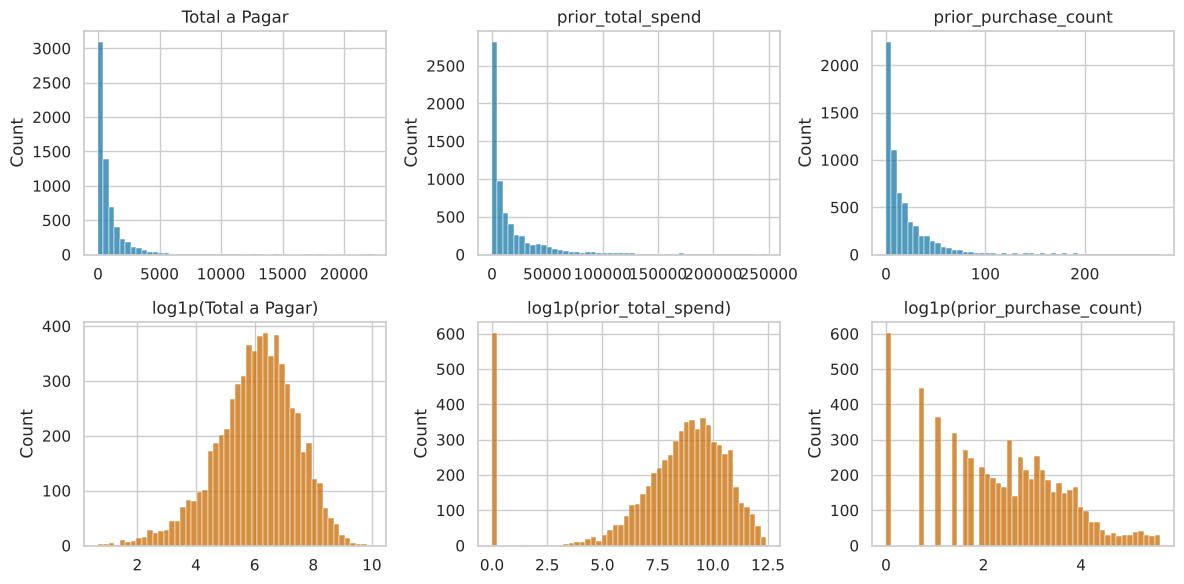

In [14]:
# Impossible values (negative or 1e9) are masked so they do not distort the shapes.
quantities = [c for c in numeric if c not in ("customer_id", "random_noise")]
valid = filled[quantities].where((filled[quantities] >= 0) & (filled[quantities] < 1e9))

print(pd.DataFrame({"skew": valid.skew(), "zeros (%)": (100 * (valid == 0).mean())})
      .sort_values("skew", ascending=False).round(1).head(12).to_string())

money = ["Total a Pagar", "prior_total_spend", "prior_purchase_count"]
fig, axes = plt.subplots(2, len(money), figsize=(4 * len(money), 6))
for i, col in enumerate(money):
    sns.histplot(valid[col].dropna(), bins=50, ax=axes[0, i], color=PLOT_BLUE)
    sns.histplot(np.log1p(valid[col].dropna()), bins=50, ax=axes[1, i], color=PLOT_ORANGE)
    axes[0, i].set(title=col, xlabel="")
    axes[1, i].set(title=f"log1p({col})", xlabel="")
plt.tight_layout()
plt.show()

The four rolling spend windows measure the same thing over different horizons, so they are compared in one graph.

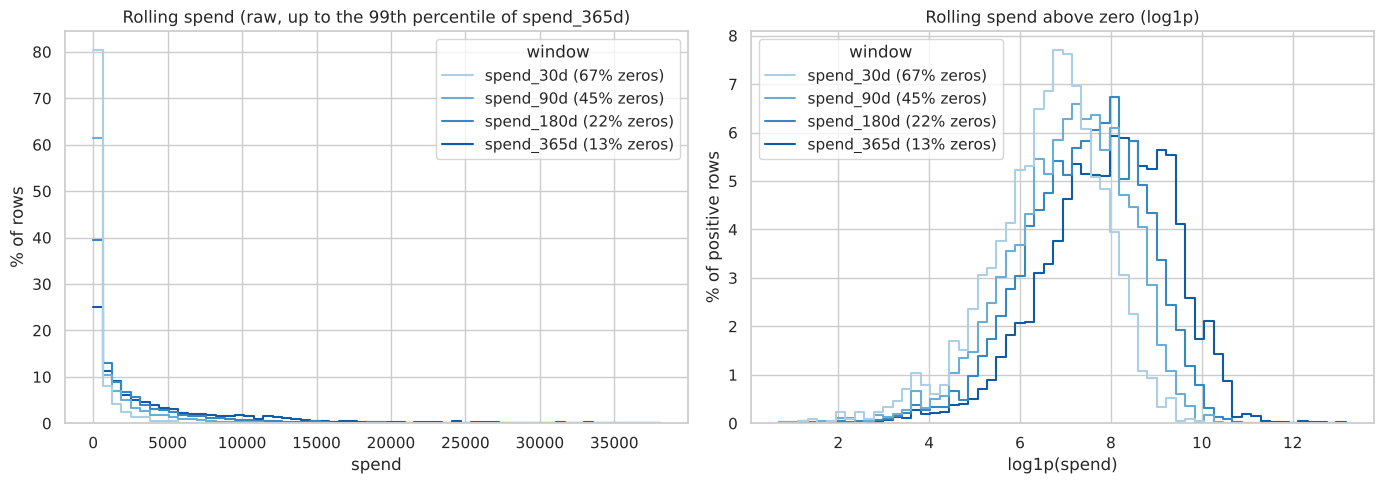

            median  skew  zeros (%)
spend_30d      0.0   5.5       67.1
spend_90d    198.5   3.7       44.7
spend_180d  1117.7   3.2       21.8
spend_365d  2426.6  18.6       12.5


In [15]:
spend_windows = ["spend_30d", "spend_90d", "spend_180d", "spend_365d"]
window_colors = sns.color_palette("Blues", len(spend_windows) + 1)[1:]   # darker = longer window

spend_long = (valid[spend_windows].melt(var_name="window", value_name="spend").dropna())
zero_share = (valid[spend_windows] == 0).mean()
labels = {w: f"{w} ({zero_share[w]:.0%} zeros)" for w in spend_windows}
spend_long["window"] = spend_long["window"].map(labels)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
upper = valid["spend_365d"].quantile(0.99)
sns.histplot(spend_long[spend_long["spend"] <= upper], x="spend", hue="window", bins=60,
             element="step", fill=False, stat="percent", common_norm=False,
             palette=window_colors, ax=axes[0])
axes[0].set(title="Rolling spend (raw, up to the 99th percentile of spend_365d)", xlabel="spend", ylabel="% of rows")
positive = spend_long[spend_long["spend"] > 0]   # zeros are reported in the legend instead
sns.histplot(positive.assign(spend=np.log1p(positive["spend"])), x="spend", hue="window", bins=60,
             element="step", fill=False, stat="percent", common_norm=False,
             palette=window_colors, ax=axes[1])
axes[1].set(title="Rolling spend above zero (log1p)", xlabel="log1p(spend)", ylabel="% of positive rows")
plt.tight_layout()
plt.show()

print(valid[spend_windows].agg(["median", "skew"]).T.assign(**{"zeros (%)": 100 * zero_share}).round(1).to_string())

<div class="alert alert-block alert-warning">

- Money and count columns are concentrated near zero with long right tails (skewness up to 27);
- Several columns are mostly zeros: `Total Desc_ Global` (98%), `Total Portes` (84%), and the 30-day counts and spend (67%);
- After `log1p` the distributions become roughly symmetric, which supports a log transform before scaling for distance-based and linear models;
- The rolling spend windows share the same right skew but differ in how many rows are exactly zero: 67% for 30 days, 45% for 90 days, 22% for 180 days and 13% for 365 days. Above zero, longer windows simply shift to higher values. In the shorter windows the zero is itself information (no purchase in that period), which `log1p` cannot spread out; a flag such as "bought in the last 90 days" may capture it better than the amount.

</div>

### 1.11 Categorical columns against the target

In [16]:
for col in categorical:
    table = (filled.groupby(col, dropna=False)[TARGET]
             .agg(rows="size", repeat_rate="mean")
             .sort_values("rows", ascending=False).round(3))
    print(f"\n{col} ({filled[col].nunique()} levels)")
    print(table.head(8).to_string())


payment_type (9 levels)
                           rows  repeat_rate
payment_type                                
Maybe Tomorrow Payment 7   4565        0.527
Maybe Tomorrow Payment 12   991        0.543
Maybe Tomorrow Payment 9    502        0.950
NaN                         195        0.564
Maybe Tomorrow Payment 10   134        0.403
Maybe Tomorrow Payment 8     40        0.325
Maybe Tomorrow Payment 2     21        0.524
Maybe Tomorrow Payment 4      9        0.444

salesperson (9 levels)
                  rows  repeat_rate
salesperson                        
VLOOKUP Master 1  4054        0.624
VLOOKUP Master 4  1461        0.394
VLOOKUP Master 9   384        0.547
VLOOKUP Master 7   201        0.483
NaN                194        0.598
VLOOKUP Master 2   123        0.602
VLOOKUP Master 3    30        0.367
VLOOKUP Master 6    12        0.000

commercial_zone (5 levels)
                             rows  repeat_rate
commercial_zone                               
Decorative Dashboar

<div class="alert alert-block alert-warning">

- `payment_type = Payment 9` repeats 95% of the time on 502 rows, against 53-54% for the two most common types: the strongest categorical signal;
- `salesperson` separates well: Master 1 (4,054 rows) 62% vs Master 4 (1,461 rows) 39%;
- `transport_method` has some informative levels (e.g. Delivery 11 at 98% on 253 rows), but 80 levels in total;
- `document_series` is flat (about 56% in every level);
- `commercial_zone` and `warehouse` are almost constant, with levels of 1 row (0% rate, not evidence);
- Missing categories repeat at about the overall rate (56-64%), so a missing value does not seem to carry a signal of its own.

</div>

### 1.12 Numeric columns by class

                                no repeat (0)  repeat (1)  ratio 1/0
days_since_previous_purchase            105.0        37.0       0.35
prior_min_purchase_value                 87.5        46.0       0.53
prior_mean_gap_days                     101.6        55.8       0.55
prior_std_gap_days                       64.9        43.6       0.67
N_ Detalhes                              12.0        10.0       0.83
Custo                                   156.8       147.9       0.94
invoice_count_current_purchase            1.0         1.0       1.00
Total a Pagar                           443.4       520.0       1.17
Total Liquido                           362.5       424.5       1.17
prior_mean_purchase_value               626.6       781.9       1.25
Total Bruto                             389.7       493.4       1.27
Total Imp_                               69.9        88.9       1.27
customer_tenure_days                    769.0      1024.0       1.33
prior_std_purchase_value          

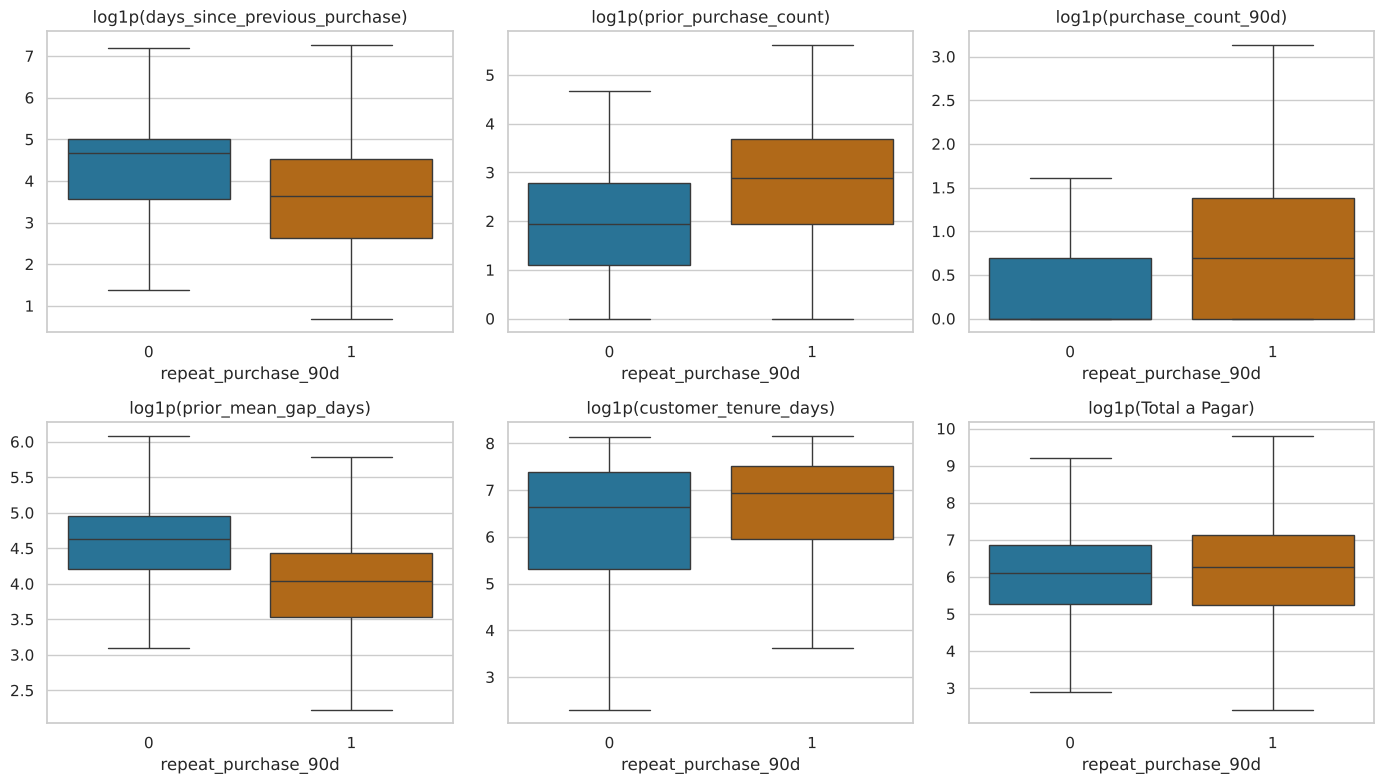

In [17]:
clean = filled.loc[~anomalies.any(axis=1)]   # training rows without any impossible value

by_class = clean.groupby(TARGET)[quantities].median().T.round(1)
by_class.columns = ["no repeat (0)", "repeat (1)"]
by_class["ratio 1/0"] = (by_class["repeat (1)"] / by_class["no repeat (0)"]).round(2)
print(by_class.sort_values("ratio 1/0").to_string())

key = ["days_since_previous_purchase", "prior_purchase_count", "purchase_count_90d",
       "prior_mean_gap_days", "customer_tenure_days", "Total a Pagar"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.ravel(), key):
    sns.boxplot(x=clean[TARGET], y=np.log1p(clean[col]), ax=ax, showfliers=False,
                hue=clean[TARGET], palette=[PLOT_BLUE, PLOT_ORANGE], legend=False)
    ax.set(title=f"log1p({col})", ylabel="")
plt.tight_layout()
plt.show()

<div class="alert alert-block alert-warning">

- Customers who repeat bought more recently (median 37 vs 105 days since the previous purchase), more often (17 vs 6 previous purchases) and at shorter intervals (56 vs 102 days);
- They also spent more in the past (`prior_total_spend` and the rolling spends are 3.8-4.7 times higher) and had at least one purchase in the previous 90 days;
- The value of the current order hardly differs between classes (`Total a Pagar` 520 vs 443);
- Repeat purchase is a matter of frequency and recency of the relationship, not of the size of this order.

</div>

### 1.13 Multivariate view

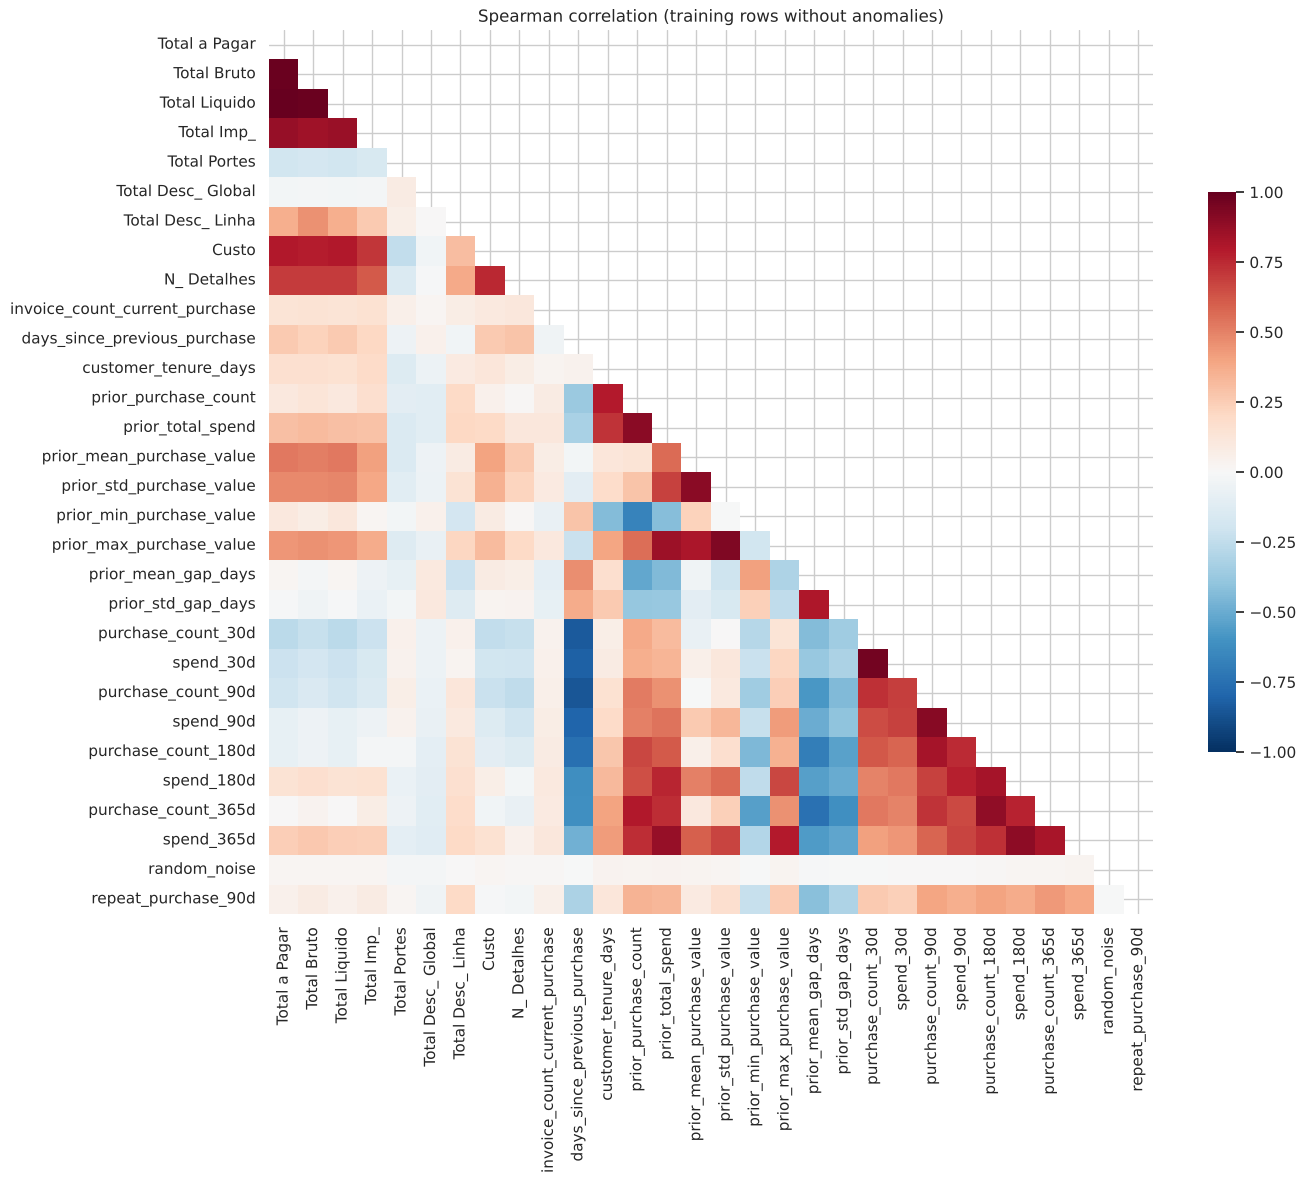

7 pairs with |rho| >= 0.9:
Total a Pagar             Total Liquido               1.000
Total Bruto               Total Liquido               0.991
Total a Pagar             Total Bruto                 0.991
purchase_count_30d        spend_30d                   0.966
prior_std_purchase_value  prior_max_purchase_value    0.937
purchase_count_90d        spend_90d                   0.910
prior_purchase_count      prior_total_spend           0.905

correlation with the target:
purchase_count_365d               0.434
prior_mean_gap_days              -0.419
purchase_count_180d               0.403
purchase_count_90d                0.391
spend_365d                        0.386
spend_180d                        0.371
spend_90d                         0.360
prior_purchase_count              0.345
prior_total_spend                 0.332
days_since_previous_purchase     -0.314
prior_std_gap_days               -0.311
purchase_count_30d                0.261
prior_max_purchase_value          0.256
spe

In [18]:
cols = quantities + ["random_noise", TARGET]
corr = clean[cols].corr(method="spearman")

plt.figure(figsize=(14, 12))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, cmap="RdBu_r", mask=mask, center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.6})
plt.title("Spearman correlation (training rows without anomalies)")
plt.tight_layout()
plt.show()

features_corr = corr.drop(index=TARGET, columns=TARGET)
upper = features_corr.where(np.triu(np.ones(features_corr.shape, dtype=bool), k=1))
pairs = upper.stack().loc[lambda s: s.abs() >= 0.9].sort_values(ascending=False)
print(f"{len(pairs)} pairs with |rho| >= 0.9:")
print(pairs.round(3).to_string())

print("\ncorrelation with the target:")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_string())

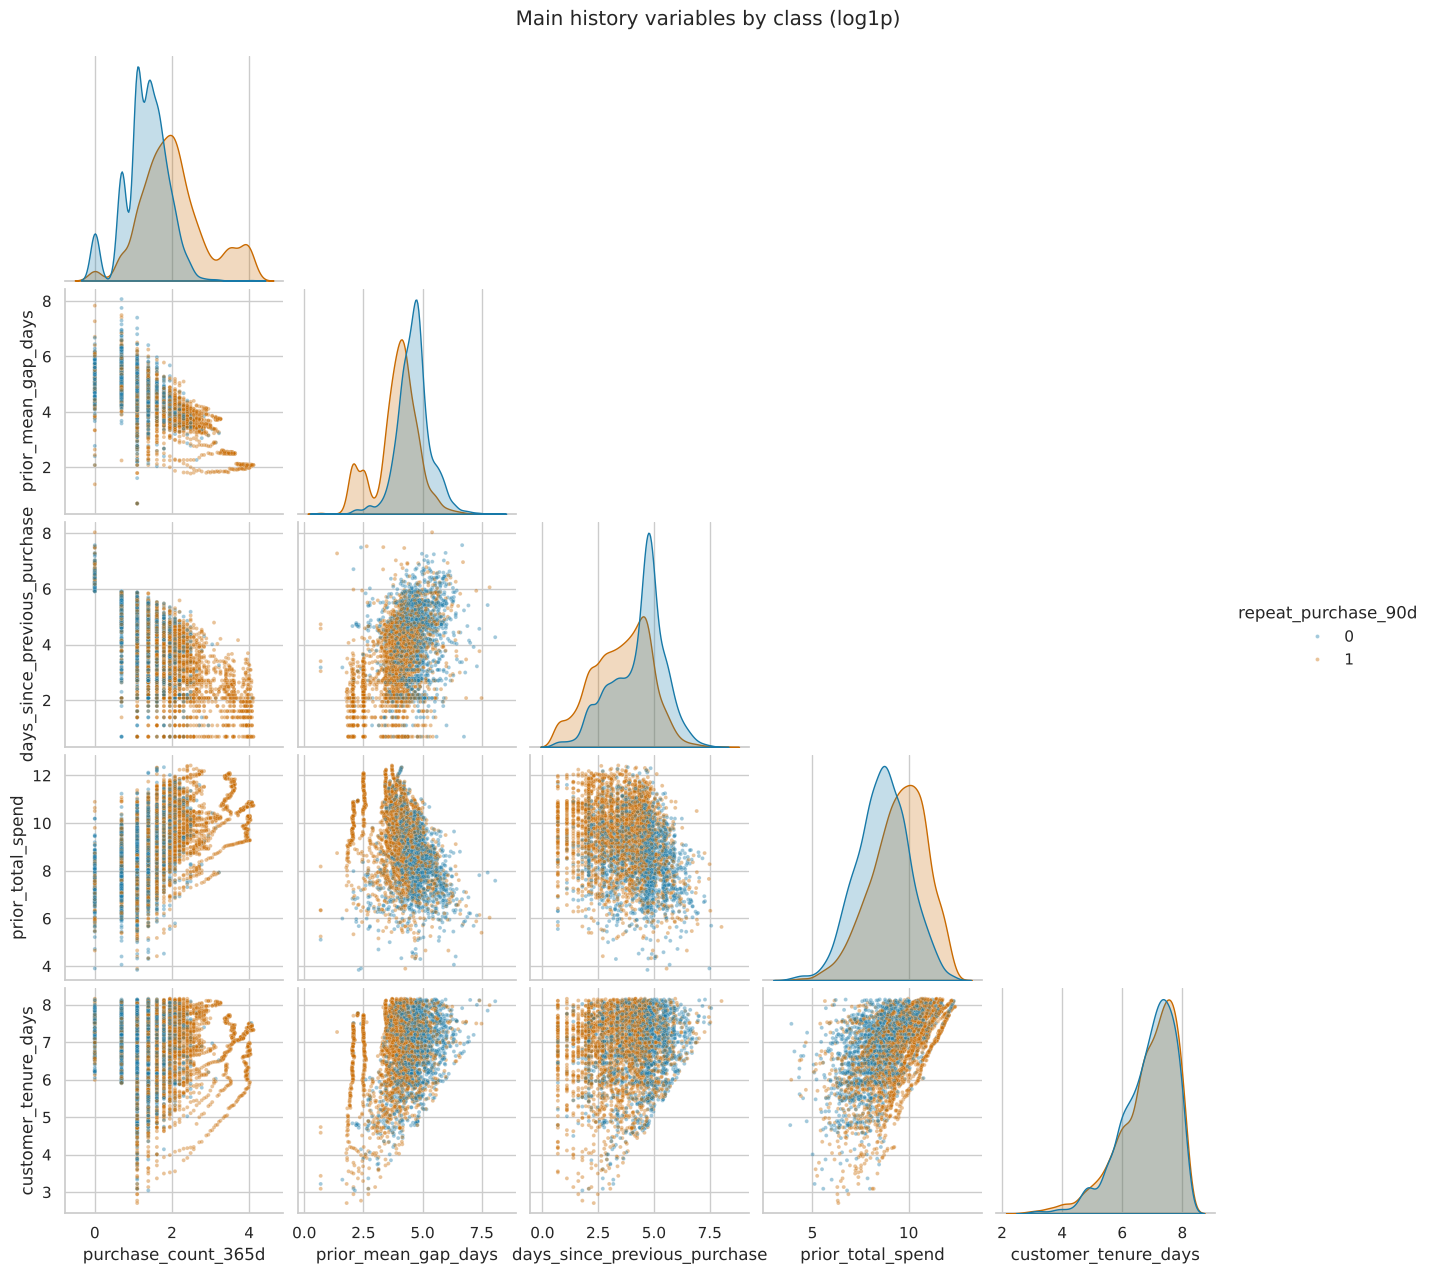

In [19]:
pair_cols = ["purchase_count_365d", "prior_mean_gap_days", "days_since_previous_purchase",
             "prior_total_spend", "customer_tenure_days"]
pair_data = np.log1p(clean[pair_cols]).assign(**{TARGET: clean[TARGET]}).dropna()

g = sns.pairplot(pair_data, hue=TARGET, corner=True, palette=[PLOT_BLUE, PLOT_ORANGE],
                 plot_kws={"s": 8, "alpha": 0.4}, diag_kws={"common_norm": False})
g.figure.suptitle("Main history variables by class (log1p)", y=1.02)
plt.show()

<div class="alert alert-block alert-warning">

- **Redundant blocks.** `Total a Pagar`, `Total Bruto` and `Total Liquido` (rho >= 0.99); count and spend in the same window (0.91-0.97); `prior_purchase_count` and `prior_total_spend` (0.90); `prior_std_purchase_value` and `prior_max_purchase_value` (0.94). Feature selection should keep one variable per block;
- **What drives the target.** History and recency: purchase counts in the windows (0.39-0.44), mean gap between purchases (-0.42), days since the previous purchase (-0.31). Current-order totals barely relate (|rho| ≤ 0.08), the only exception being line discounts (`Total Desc_ Linha`, 0.20);
- Even the strongest variables only reach |rho| ≈ 0.4 and the classes overlap heavily in the pair plot, so no single feature separates them: the model has to combine them;
- `random_noise` sits at -0.007, the reference for "no relation".

</div>

### 1.14 Stability over time

               rows  repeat_rate
purchase_date                   
2015            335        0.534
2016            420        0.514
2017            670        0.633
2018            716        0.538
2019            646        0.522
2020            670        0.594
2021            782        0.549
2022            628        0.481
2023            767        0.581
2024            757        0.602
2025             78        0.628


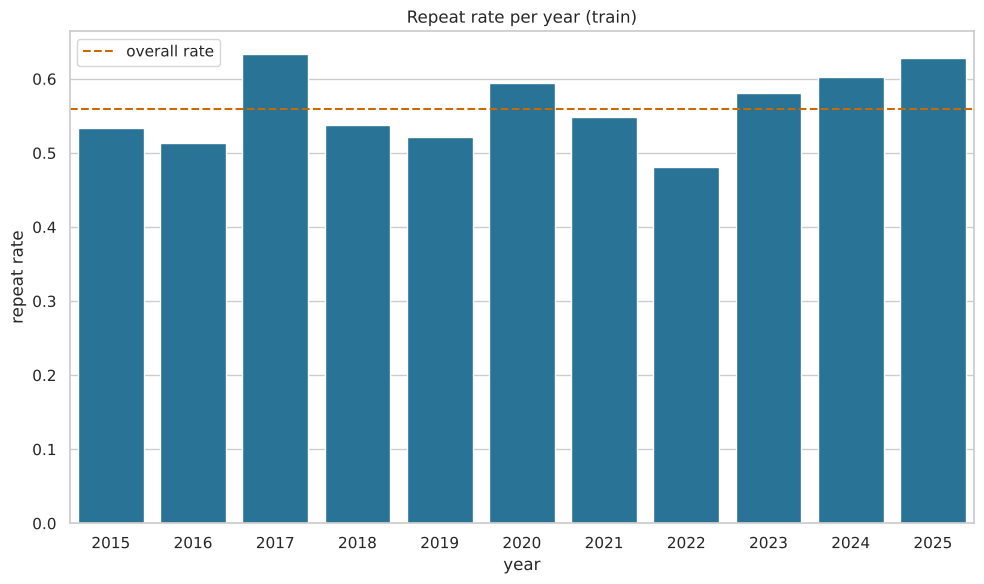

In [20]:
by_year = filled.groupby(filled["purchase_date"].dt.year)[TARGET].agg(rows="size", repeat_rate="mean").round(3)
by_year.index = by_year.index.astype(int)
print(by_year.to_string())

fig, ax = plt.subplots(figsize=FIGSIZE)
sns.barplot(x=by_year.index.astype(str), y=by_year["repeat_rate"], color=PLOT_BLUE, ax=ax)
ax.axhline(filled[TARGET].mean(), color=PLOT_ORANGE, linestyle="--", label="overall rate")
ax.set(xlabel="year", ylabel="repeat rate", title="Repeat rate per year (train)")
ax.legend()
plt.tight_layout()
plt.show()

<div class="alert alert-block alert-warning">

- The repeat rate moves between 48% (2022) and 63% (2017) with no consistent trend, so the relation between features and target should broadly hold in the test period;
- However, the most recent years (2023-2025) are all above the overall rate (58-63%). Since test comes right after train, the share of repeat purchases in test may be slightly higher than the training average. A time-ordered validation, whose last folds are the most recent purchases, reflects this better than a random split;
- 2015 (from July) and especially 2025 (78 rows, up to February) are partial years, so their rates are less reliable.

</div>

### 1.15 Summary: what the exploration means for the next steps

| Finding | Decision |
|---|---|
| 65 empty training rows (and the 10 "duplicates") | Drop them from train; test has none |
| Structural gaps in `prior_*` (0, 1 or 2 previous purchases) | Keep, add history flags by a fixed rule, impute inside the pipeline |
| Sentinels (1e9), negatives (-4 days), inflated means, impossible maxima | Set to missing by a fixed rule in train and test; recompute `prior_mean` from total / count |
| Strong right skew in money and count columns | `log1p` before scaling |
| Redundant blocks (rho ≥ 0.9) | One variable per block in feature selection |
| `ID`, `customer_id`, `random_noise`, raw `purchase_date` | Not used as features |
| Unseen levels in test, 80-level `transport_method`, near-constant `warehouse` and `commercial_zone` | Encoder that ignores unknown levels; group rare levels or drop near-constant columns |
| `clientes.csv`: safe join, few usable columns | Test `country_or_region`, `commercial_region`, `customer_since_year` in validation |
| Test lies after train; customers repeat; recent years above average | `TimeSeriesSplit` on rows sorted by `purchase_date`, with all preprocessing fitted inside each fold |